# Mushroom Data Classification Report - Team 10

This notebook explores a dataset consisting of varying mushroom data and its safety towards consumption. In this assignment, we aim to understand the characteristics of the data and develop a Machine Learning model to classify a given record based on a mushroom's edibility.

The analysis begins with an examination of the dataset's structure, features, and data quality. During this analysis, the data will simultaneously be prepared for being trained into a subset of ML models.

Different preprocessing strategies and model parameters are evaluated, with the objective of improving classification performance.

## 1 - EDA & Data Preparation

Before building a Machine Learning model, it is important to understand the structure and quality of the dataset. An Exploratory Data Analysis helps us identify patterns and understand the different values the data might provide for us.

In this section, the dataset is examined to understand its dimensions, column names, data types, and overall completeness. Based on these observations the data is prepared for modelling.

### Imported Libraries and Data Loading

The first step is to import the Python libraries required for data analysis and visualization. Pandas is used to load and examine the dataset. Seaborn and Matplotlib are used to create visualizations that help identify patterns, explore feature distributions.

In [81]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

The dataset is loaded from a CSV file into a Pandas DataFrame. To ensure consistent naming conventions and simplify future data manipulation, the column names are converted to lowercase, leading and trailing whitespace is removed, and hyphens are replaced with underscores.

The initial inspection reveals that the dataset contains a substantial number of missing values across several columns. Most of the features are also categorical, while only a small number contain numerical measurements.

In [82]:
mush = pd.read_csv('mushroom_project_dataset.csv')

mush.columns = mush.columns.str.strip().str.lower().str.replace('-', '_', regex=False)

mush.head()

,cap_diameter,stem_height,stem_width,spore_print_color,gill_color,habitat,season,ring_type,cap_shape,stem_surface,jumbled_noise_0,jumbled_noise_1,class
0,NaN,6.42,13.51,NaN,NaN,d,u,g,x,NaN,x,c,p
1,6.99,7.68,18.76,NaN,w,d,a,f,f,s,f,f,e
2,5.78,7.67,8.21,NaN,r,d,u,f,c,NaN,c,x,p
3,6.34,8.34,11.06,NaN,NaN,d,a,z,x,NaN,x,b,p
4,NaN,5.67,12.78,NaN,n,d,NaN,f,x,NaN,s,s,e


In [83]:
mush.info()

display(mush.nunique().rename('Amount of unique values').to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   cap_diameter       2968 non-null   float64
 1   stem_height        3987 non-null   float64
 2   stem_width         4605 non-null   float64
 3   spore_print_color  260 non-null    object 
 4   gill_color         4011 non-null   object 
 5   habitat            3996 non-null   object 
 6   season             4027 non-null   object 
 7   ring_type          4423 non-null   object 
 8   cap_shape          4594 non-null   object 
 9   stem_surface       1641 non-null   object 
 10  jumbled_noise_0    4594 non-null   object 
 11  jumbled_noise_1    4594 non-null   object 
 12  class              5000 non-null   object 
dtypes: float64(3), object(10)
memory usage: 507.9+ KB


,Amount of unique values
cap_diameter,1238
stem_height,1086
stem_width,2221
spore_print_color,7
gill_color,12
habitat,8
season,4
ring_type,8
cap_shape,7
stem_surface,8


### Understanding the features

To better understand the meaning of each variable, a feature dictionary is created based on the original dataset's documentation. It provides an overview of the features, their data types, and descriptions.

The dictionary distinguishes between metric features, which represent numerical measurements, and nominal features, which describe categorical characteristics of the mushrooms. It also identifies class as the binary target variable, where e represents edible mushrooms and p represents poisonous mushrooms or mushrooms of unknown edibility.

In [84]:
feature_info = {
    "cap-diameter": {
        "Type": "Metric",
        "Description": "Cap diameter in centimetres",
        "Category codes": "Continuous numeric value"
    },
    "cap-shape": {
        "Type": "Nominal",
        "Description": "Shape of the mushroom cap",
        "Category codes": "b: bell, c: conical, x: convex, f: flat, s: sunken, p: spherical, o: other"
    },
    "cap-surface": {
        "Type": "Nominal",
        "Description": "Surface texture of the cap",
        "Category codes": "i: fibrous, g: grooves, y: scaly, s: smooth, h: shiny, l: leathery, k: silky, t: sticky, w: wrinkled, e: fleshy"
    },
    "cap-color": {
        "Type": "Nominal",
        "Description": "Colour of the mushroom cap",
        "Category codes": "n: brown, b: buff, g: gray, r: green, p: pink, u: purple, e: red, w: white, y: yellow, l: blue, o: orange, k: black"
    },
    "does-bruise-bleed": {
        "Type": "Nominal",
        "Description": "Whether the mushroom bruises or bleeds",
        "Category codes": "t: yes, f: no"
    },
    "gill-attachment": {
        "Type": "Nominal",
        "Description": "How the gills attach to the stem",
        "Category codes": "a: adnate, x: adnexed, d: decurrent, e: free, s: sinuate, p: pores, f: none, ?: unknown"
    },
    "gill-spacing": {
        "Type": "Nominal",
        "Description": "Spacing between the gills",
        "Category codes": "c: close, d: distant, f: none"
    },
    "gill-color": {
        "Type": "Nominal",
        "Description": "Colour of the gills",
        "Category codes": "Same colour codes as cap-color; f: none"
    },
    "stem-height": {
        "Type": "Metric",
        "Description": "Stem height in centimetres",
        "Category codes": "Continuous numeric value"
    },
    "stem-width": {
        "Type": "Metric",
        "Description": "Stem width in millimetres",
        "Category codes": "Continuous numeric value"
    },
    "stem-root": {
        "Type": "Nominal",
        "Description": "Shape or structure of the stem root",
        "Category codes": "b: bulbous, s: swollen, c: club, u: cup, e: equal, z: rhizomorphs, r: rooted"
    },
    "stem-surface": {
        "Type": "Nominal",
        "Description": "Surface texture of the stem",
        "Category codes": "Same texture codes as cap-surface; f: none"
    },
    "stem-color": {
        "Type": "Nominal",
        "Description": "Colour of the stem",
        "Category codes": "Same colour codes as cap-color; f: none"
    },
    "veil-type": {
        "Type": "Nominal",
        "Description": "Type of veil",
        "Category codes": "p: partial, u: universal"
    },
    "veil-color": {
        "Type": "Nominal",
        "Description": "Colour of the veil",
        "Category codes": "Same colour codes as cap-color; f: none"
    },
    "has-ring": {
        "Type": "Nominal",
        "Description": "Whether a ring is present",
        "Category codes": "t: ring present, f: no ring"
    },
    "ring-type": {
        "Type": "Nominal",
        "Description": "Type of ring",
        "Category codes": "c: cobwebby, e: evanescent, r: flaring, g: grooved, l: large, p: pendant, s: sheathing, z: zone, y: scaly, m: movable, f: none, ?: unknown"
    },
    "spore-print-color": {
        "Type": "Nominal",
        "Description": "Colour of the spore print",
        "Category codes": "Same colour codes as cap-color"
    },
    "habitat": {
        "Type": "Nominal",
        "Description": "Habitat where the mushroom grows",
        "Category codes": "g: grasses, l: leaves, m: meadows, p: paths, h: heaths, u: urban, w: waste, d: woods"
    },
    "season": {
        "Type": "Nominal",
        "Description": "Season associated with the mushroom",
        "Category codes": "s: spring, u: summer, a: autumn, w: winter"
    },
    "class": {
        "Type": "Binary target",
        "Description": "Edibility label",
        "Category codes": "e: edible, p: poisonous or unknown edibility"
    }
}

feature_df = pd.DataFrame.from_dict(
    feature_info,
    orient="index"
)

feature_df.index.name = "Feature"

print("MUSHROOM DATASET — FEATURE DICTIONARY")
display(feature_df)


MUSHROOM DATASET — FEATURE DICTIONARY


,Type,Description,Category codes
Feature,,,
cap-diameter,Metric,Cap diameter in centimetres,Continuous numeric value
cap-shape,Nominal,Shape of the mushroom cap,"b: bell, c: conical, x: convex, f: flat, s: su..."
cap-surface,Nominal,Surface texture of the cap,"i: fibrous, g: grooves, y: scaly, s: smooth, h..."
cap-color,Nominal,Colour of the mushroom cap,"n: brown, b: buff, g: gray, r: green, p: pink,..."
does-bruise-bleed,Nominal,Whether the mushroom bruises or bleeds,"t: yes, f: no"
gill-attachment,Nominal,How the gills attach to the stem,"a: adnate, x: adnexed, d: decurrent, e: free, ..."
gill-spacing,Nominal,Spacing between the gills,"c: close, d: distant, f: none"
gill-color,Nominal,Colour of the gills,Same colour codes as cap-color; f: none
stem-height,Metric,Stem height in centimetres,Continuous numeric value


### Target

First we cover the target variable: class. When counting all records of each type, we discover there are 2 possible results, those being 'poisonous' and 'edible.'

By visualizing the distribution, it becomes clear about 2/3 of the results consist of edible mushrooms, meaning there is a relative imbalance in the dataset.

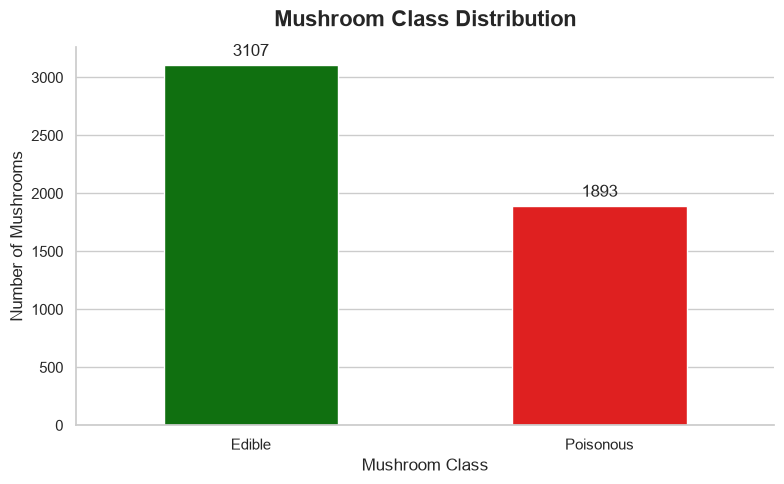

In [85]:
sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=mush,
    x='class',
    hue='class',
    order=['e', 'p'],
    palette={'e': 'green', 'p': 'red'},
    legend=False,
    width=0.5
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fmt='%.0f')
    
ax.set_xticks([0, 1])
ax.set_xticklabels(['Edible', 'Poisonous'])

plt.title('Mushroom Class Distribution', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Mushroom Class', fontsize=12)
plt.ylabel('Number of Mushrooms', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

### Missing Values

Since the initial inspection revealed a substantial amount of missing data, this visualization examines the number of null values in each feature. This analysis is important because missing data can reduce the amount of information available to the model and may introduce bias if the missingness is not random.

Through this code we observe that 'spore print color', 'stem surface', and 'cap diameter' have the highest amount of missing values throughout the csv file. 

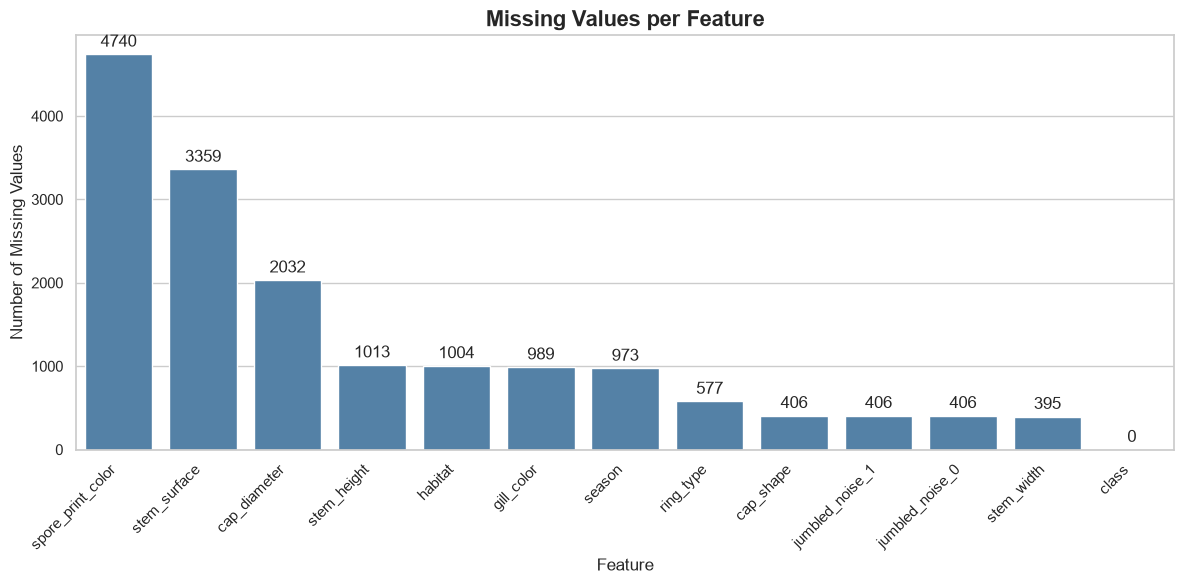

In [86]:
null_counts = mush.isnull().sum().sort_values(ascending=False)

null_df = null_counts.reset_index()
null_df.columns = ['Feature', 'Missing Values']

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=null_df,
    x='Feature',
    y='Missing Values',
    color='steelblue'
)

ax.bar_label(ax.containers[0], padding=3, fmt='%d')

plt.title('Missing Values per Feature', fontsize=16, fontweight='bold')
plt.xlabel('Feature')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Numerical features

The numerical features are examined to understand their distributions, ranges, and potential outliers. Histograms provide an overview of the frequency of different measurement values, while boxplots help identify extreme observations.

The histograms show that 'cap diameter', 'stem height', and 'stem width' are all more concentrated towards the lower values, with some small outliers around the higher measurements.

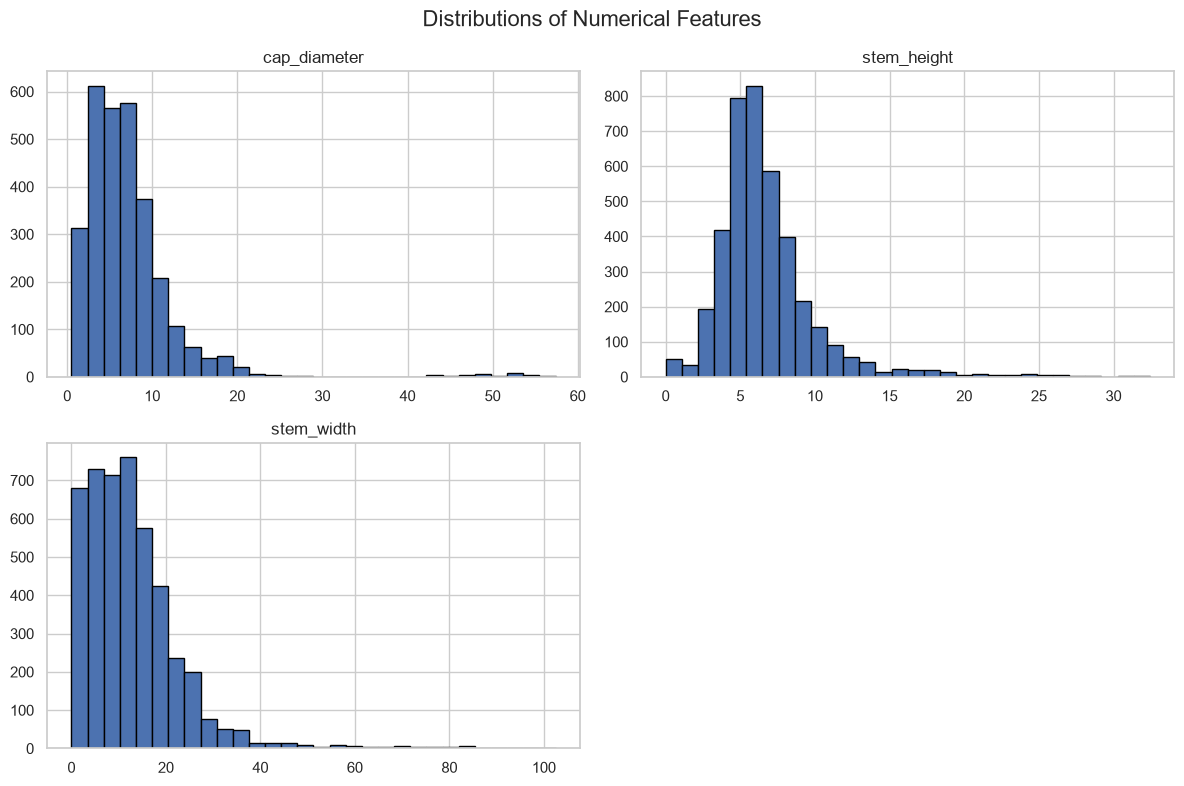

In [87]:
numerical_cols = mush.select_dtypes(include='number').columns.tolist()

if numerical_cols:
    mush[numerical_cols].hist(
        figsize=(12, 8),
        bins=30,
        edgecolor='black'
    )
    plt.suptitle('Distributions of Numerical Features', fontsize=16)
    plt.tight_layout()
    plt.show()

The boxplot comparisons show that edible mushrooms overall have a slightly higher median (with an exception for stem height) than the poisonous counterpart. While distribution is spread out a bit more, there still remains a decently large overlap, meaning that relying on the edible class alone will not be enough.

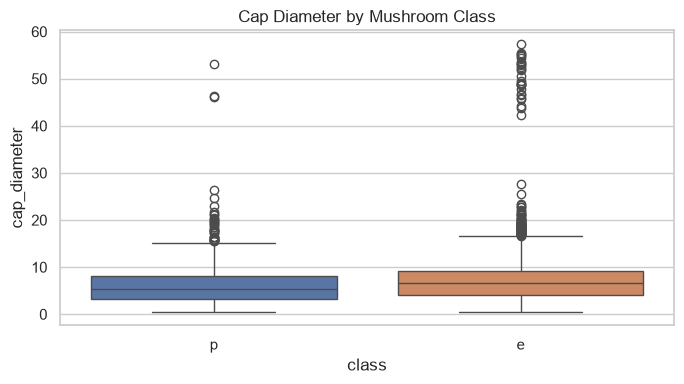

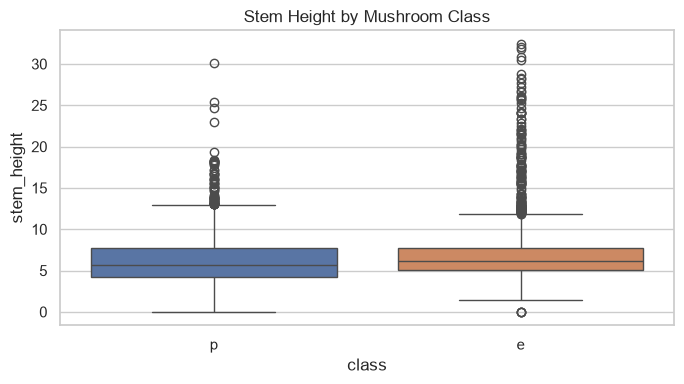

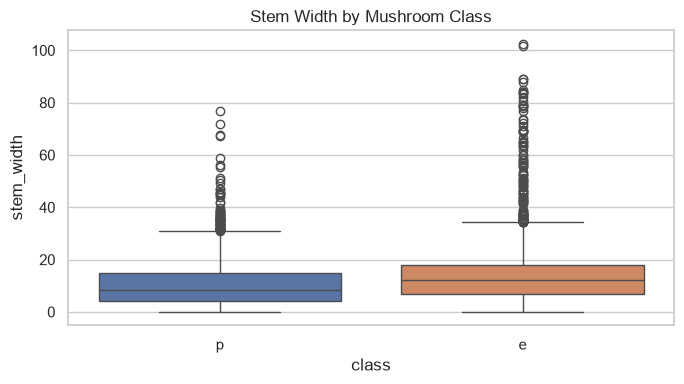

In [88]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=mush, x='class', y=col, hue='class', legend=False)
    plt.title(f'{col.replace("_", " ").title()} by Mushroom Class')
    plt.tight_layout()
    plt.show()

### Noise features

In the assignment it was made clear several columns of static noise were added to increase the difficulty of the dataset. Such features may add complexity without improving predictive performance. Therefore it is important to know how we should evaluate these later on.

In [89]:
noise_cols = [col for col in mush.columns if 'jumbled_noise' in col]

for col in noise_cols:
    print(f'\n{col}')
    display(mush[col].value_counts(dropna=False).head(20).to_frame('Count'))
    display(pd.crosstab(mush[col], mush['class'], normalize='index').round(3))


jumbled_noise_0


,Count
jumbled_noise_0,
x,2060
f,1078
s,533
NaN,406
b,354
o,218
p,207
c,144


class,e,p
jumbled_noise_0,,
b,0.624,0.376
c,0.569,0.431
f,0.620,0.380
o,0.656,0.344
p,0.638,0.362
s,0.614,0.386
x,0.629,0.371



jumbled_noise_1


,Count
jumbled_noise_1,
x,2060
f,1078
s,533
NaN,406
b,354
o,218
p,207
c,144


class,e,p
jumbled_noise_1,,
b,0.613,0.387
c,0.521,0.479
f,0.647,0.353
o,0.550,0.450
p,0.623,0.377
s,0.589,0.411
x,0.634,0.366


### Conclusion

The EDA revealed that the dataset contains a large amount of missing data, predominantly in categorical features. Most of the dataset consists of this categorical data, with only a small amount of numerical info, which will require a form of encoding in the training process. We also found out there's a moderate imbalance in the target class that will have to be taken into account.

The next step is to ready the data for Machine Learning.

## 2 - Model Training and Prediction

Following the exploratory data analysis and data preparation, the next step is to develop a machine learning model capable of predicting mushroom edibility. In this section, the dataset is prepared for training by separating the target variable from the input features and applying appropriate techniques.

A Random Forest classifier is used to learn patterns in the data and predict whether a mushroom is edible or poisonous or of unknown edibility. The model's performance is then evaluated using the right classification metrics, providing insight into its predictive ability and its potential for further improvement.

## 2.1.1 - Random Forest First Version

The libraries required for model training, preprocessing, and evaluation are imported. Scikit-learn provides the tools needed to split the dataset into training and testing sets, build a Random Forest classifier, and construct a preprocessing pipeline.

The SimpleImputer is used to handle missing values, while OneHotEncoder converts categorical features into a numerical representation that the model can process. A ColumnTransformer applies the appropriate preprocessing to numerical and categorical features separately, and a Pipeline combines these steps with the classifier into a single workflow.

Lastly, evaluation tools such as accuracy, the classification report, and the confusion matrix are imported to assess the model's predictive performance on unseen data.

In [90]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Before training the model, the dataset is divided into input features and the target variables. The data is then split into training and testing sets, with 82% allocated for training and a balanced 18% reserved for testing. The training set is used to create the model, while the test set provides an evaluation of its performance on unseen data.

In [91]:
X = mush.drop(columns=['class'])
y = mush['class']

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    random_state=42,
    test_size=0.18,
    stratify=y
)

Before training the classifier, a preprocessing pipeline is created to handle missing values and convert the features into a format suitable for machine learning. The numerical and categorical columns are identified separately so that each type can be processed using an appropriate technique.

For numerical features, missing values are replaced with the median, which is less sensitive to extreme values than the mean. For categorical features, missing values are replaced with the most frequent category, after which one-hot encoding transforms the categories into numerical variables. A ColumnTransformer combines these operations into a single preprocessing step.

In [93]:
numerical_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

numeric_transformer = SimpleImputer(strategy='median')
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

A machine learning pipeline is created by combining the preprocessing steps with a Random Forest classifier. The classifier is configured with 200 decision trees and numerous other hyperparameters of default complexity. Later we will aim to improve upon these.

Finally, the pipeline is fitted to the training data.

In [94]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=3,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['e','p']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['cap_diameter','stem_height','stem_width',...,'stem_surface', 'jumbled_noise_0','jumbled_noise_1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

After training, the Random Forest classifier is evaluated using the test set, which resulted in an accuracy of roughly 78%. A classification report is also generated to provide a more detailed evaluation. We discover that the dataset responds more positively to edible mushrooms with a recall of 90%, while poisonous sits significantly lower at 60%, meaning that the model fails to identify a decent proportion of these samples.

The confusion matrix also details that the program has a tendency to apply many false positives actual poisonous types.

Model accuracy: 78.33%

              precision    recall  f1-score   support

           e       0.78      0.90      0.84       559
           p       0.78      0.60      0.68       341

    accuracy                           0.78       900
   macro avg       0.78      0.75      0.76       900
weighted avg       0.78      0.78      0.78       900



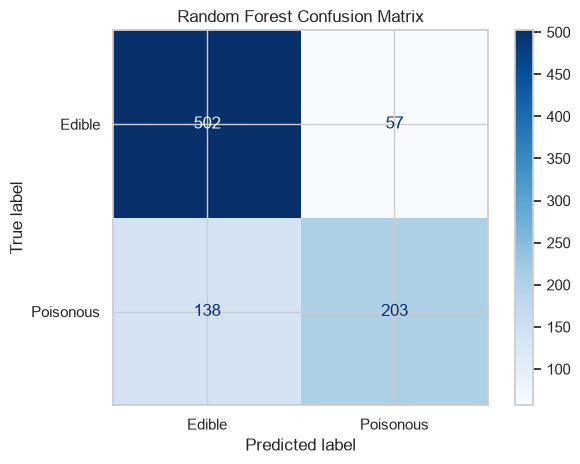

In [95]:
y_pred = model.predict(X_test)
print(f"Model accuracy: {model.score(X_test, y_test) * 100:.2f}%\n")

print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Edible', 'Poisonous'],
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.show()

## 2.1.2 - Improving the Random Forest Model

The initial Random Forest model achieved an accuracy of 78.33%, but we believe this can be improved upon.

In this section, we apply the findings of the EDA and make sure the model is refined by investigating alternative hyperparameter settings and evaluating their impact on classification performance.

Two additional tools are imported to support the model improvement process. The clone function from scikit-learn creates a copy of an existing estimator, making it useful for comparing alternative model setups. NumPy is imported to support numerical operations.

In [96]:
from sklearn.base import clone
import numpy as np

To improve the model, we tried removing the jumbled noise features upon we realized that solely 'jumbled noise 0' had a negative impact on the model's predictability. Due to its irrelevance we removed it from the final equation.

The target variable, class, is once again separated from the remaining input features, and the dataset is split into training and testing sets using the same 82/18 ratio, random seed, and stratification strategy as before.

In [97]:
X = mush.drop(columns=["class", "jumbled_noise_0"])
y = mush["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.18,
    random_state=42,
    stratify=y
)

X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

### Encoding and filling missing data

First, categorical features are once again transformed into numerical representations through one-hot encoding. 

The preprocessor is then again fitted on the training data.

In [98]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

initial_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_encoded = initial_preprocessor.fit_transform(X_train_raw)
X_test_encoded = initial_preprocessor.transform(X_test_raw)

Through the EDA, we found that because of the large amount of missing data in some features, the classification performed worse. By filling some of these values, we hoped to achieve a better final score during our prediction process. For this we focussed mostly on the categories with the most amounts of missing data.

After experimenting for a bit, we found that filling in these values for solely the feature with the most amount of missing entries, resulted in a better prediction. To do this we made use of a Proximity Matrix. The idea is to measure how similar two mushroom samples are based on how often they end up in the same leaf nodes accross the trees of a Random Forest.

First, synthetic samples are generated by independently permuting each feature in the encoded training data. This disrupts the relationships between features and creates an artificial comparison group. A Random Forest is then trained to distinguish the original training samples from these synthetic samples.

Next, the trained forest assigns each training and test sample to a leaf node in every tree. One-hot encoding is applied to these leaf assignments so that samples can be compared efficiently. The proximity between two samples is calculated as the proportion of trees in which they reach the same leaf node.

The resulting training and test proximity matrices quantify similarities between samples in the learned tree structure. These matrices can subsequently be used to identify similar training observations and investigate whether proximity-based imputation improves the classification model.

In [99]:
rng = np.random.default_rng(42)

X_train_dense = (
    X_train_encoded.toarray()
    if hasattr(X_train_encoded, "toarray")
    else np.asarray(X_train_encoded)
)

X_synthetic = np.column_stack([
    rng.permutation(X_train_dense[:, j])
    for j in range(X_train_dense.shape[1])
])

X_for_proximity = np.vstack([X_train_dense, X_synthetic])
proximity_labels = np.r_[
    np.ones(len(X_train_dense)),
    np.zeros(len(X_synthetic))
]

proximity_forest = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

proximity_forest.fit(X_for_proximity, proximity_labels)

train_leaves = proximity_forest.apply(X_train_encoded)
test_leaves = proximity_forest.apply(X_test_encoded)

leaf_encoder = OneHotEncoder(handle_unknown="ignore")
train_leaf_matrix = leaf_encoder.fit_transform(train_leaves)
test_leaf_matrix = leaf_encoder.transform(test_leaves)

n_trees = train_leaves.shape[1]

train_proximity = (
    train_leaf_matrix @ train_leaf_matrix.T
).toarray() / n_trees

test_proximity = (
    test_leaf_matrix @ train_leaf_matrix.T
).toarray() / n_trees


Using the proximity matrices, a function is implemented to estimate missing values in the spore_print_color feature. Rather than replacing missing values with the most frequent categories, this method uses similar training samples to determine a replacement.

For each sample with a missing spore print colour, the function identifies up to 30 nearby training samples based on their Random Forest proximity scores. Neighbours with known spore print colours are considered, and their similarity scores are combined by category. The category with the highest total similarity weight is selected as the imputed value. If no positive similarity scores are available, the function falls back to the most frequent colour in the reference data. The function is then applied separately to the training and test sets.

In [100]:
def impute_spore_color(query_df, reference_df, proximity, k=30):
    result = query_df.copy()

    reference_colors = reference_df["spore_print_color"]
    available_colors = reference_colors.notna().to_numpy()

    missing_rows = np.flatnonzero(
        result["spore_print_color"].isna().to_numpy()
    )

    for row_idx in missing_rows:
        similarities = proximity[row_idx].copy()
        similarities[~available_colors] = -1

        valid_count = np.sum(similarities >= 0)
        if valid_count == 0:
            continue

        neighbor_count = min(k, int(valid_count))
        neighbor_idx = np.argsort(similarities)[-neighbor_count:]

        neighbor_idx = neighbor_idx[
            similarities[neighbor_idx] >= 0
        ]

        neighbor_colors = reference_colors.iloc[neighbor_idx]
        neighbor_weights = similarities[neighbor_idx]

        scores = {}
        for color, weight in zip(
            neighbor_colors.to_numpy(),
            neighbor_weights
        ):
            scores[color] = scores.get(color, 0.0) + weight

        if scores and max(scores.values()) > 0:
            result.iloc[
                row_idx,
                result.columns.get_loc("spore_print_color")
            ] = max(scores, key=scores.get)
        else:
            result.iloc[
                row_idx,
                result.columns.get_loc("spore_print_color")
            ] = reference_colors.mode().iloc[0]

    return result


X_train_imputed = impute_spore_color(
    X_train_raw, X_train_raw, train_proximity
)

X_test_imputed = impute_spore_color(
    X_test_raw, X_train_raw, test_proximity
)

A final preprocessing pipeline is constructed. The Random Forest classifier is once again configured with rather default hyperparameters, which will be handled in the following part of this report. The model is trained using the prepared training data and evaluated on the test set.

In [103]:
other_categorical_cols = [
    col for col in categorical_cols
    if col != "spore_print_color"
]

final_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("other_cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), other_categorical_cols),

    ("spore", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), ["spore_print_color"])
])

model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=3,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train_imputed, y_train)

y_pred = model.predict(X_test_imputed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8055555555555556
              precision    recall  f1-score   support

           e       0.82      0.89      0.85       559
           p       0.78      0.67      0.72       341

    accuracy                           0.81       900
   macro avg       0.80      0.78      0.79       900
weighted avg       0.80      0.81      0.80       900



The improved Random Forest achieves an accuracy of 80.56%, representing a small increase from the previous version of the program. The macro-averaged F1-score also improves from 0.76 to 0.79, indicating a better balance between the two classes. 

### Gridsearch and Hyperparameters

To further improve the Random Forest classifier, a hyperparameter search is performed using GridSearchCV. Hyperparameters determine how the model is trained and how complex its decision trees can become. Selecting suitable values can improve predictive performance and reduce the risk of overfitting or underfitting.

The GridSearchCV and StratifiedKFold utilities are imported from scikit-learn to support systematic hyperparameter optimization. GridSearchCV evaluates different combinations of model parameters and identifies the configuration that achieves the best cross-validation score. StratifiedKFold divides the training data into multiple folds while maintaining approximately the same class proportions in each fold.

In [104]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

Before running the grid search, the Random Forest classifier is placed inside a pipeline together with the previously defined preprocessing steps. This ensures that missing-value imputation and categorical encoding are performed consistently during cross-validation.

In [105]:
model = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

A grid of hyperparameter values is defined to specify which Random Forest configurations will be evaluated during the search. The grid explores five parameters: the number of decision trees (n_estimators), the maximum tree depth (max_depth), the minimum number of samples required to split a node (min_samples_split), the minimum number of samples required in a leaf (min_samples_leaf), and the number of features considered at each split (max_features).

These parameters aim to influence the complexity of the model. 

In [106]:
param_grid = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [20, 30, None],
    "classifier__min_samples_split": [2, 3, 4],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__max_features": ["sqrt", None]
}

The grid search is configured to evaluate the defined hyperparameter combinations using five-fold stratified cross-validation. The search evaluates all 72 hyperparameter combinations across five folds, resulting in 360 model fits.

In [107]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=False
)

grid_search.fit(X_train_imputed, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [20, 30, ...], 'classifier__max_features': ['sqrt', None], 'classifier__min_samples_leaf': [1, 2], 'classifier__min_samples_split': [2, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` defau

In [108]:
results = pd.DataFrame(grid_search.cv_results_)

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 4))

Best hyperparameters:
{'classifier__max_depth': 20, 'classifier__max_features': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 300}

Best cross-validation macro F1:
0.757


After fitting the model once more, we found our most suitable hyperparams and will now apply these onto the final trained version of the model.

In [109]:
best_model = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("classifier", RandomForestClassifier(
        **{
            key.replace("classifier__", ""): value
            for key, value in grid_search.best_params_.items()
        },
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

best_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['e','p']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['cap_diameter','stem_height','stem_width',...,'cap_shape','stem_surface', 'jumbled_noise_1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('other_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

Accuracy: 0.82
              precision    recall  f1-score   support

           e       0.83      0.89      0.86       559
           p       0.80      0.70      0.75       341

    accuracy                           0.82       900
   macro avg       0.82      0.80      0.80       900
weighted avg       0.82      0.82      0.82       900



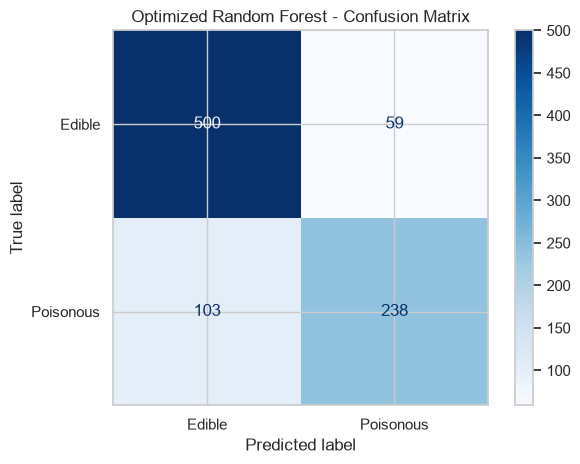

In [110]:
y_pred = best_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Edible", "Poisonous"],
    cmap="Blues",
    values_format="d"
)

plt.title("Optimized Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

After selecting the best hyperparameter configuration, the Random Forest once again performs a little better on the different scoring metrics. The model performed better at identifying edible mushrooms, achieving a recall of 89% and an F1-score of 0.86. For poisonous or unknown-edibility mushrooms, recall increased to 70%, meaning the model correctly identified 70% of the samples in this class. 

## 2.2.1 - Gradient Boosting

As an alternative to the optimized RF model, we also took a look at Gradient Boosting. This model will make use of the same training and test datasets to ensure a better comparison with the previous Random Forest models.

We once more import a new library to support us in the classifying process. This time we obviously need to import the GradientBoostingClassifier which the program cannot operate without.

In [111]:
from sklearn.ensemble import GradientBoostingClassifier

Just like in the previous part of the document, we create a pipeline that combines data preprocessing and model data into one workflow. Due to the different model, we can now also dedicate a certain learning rate, which might lead to a more gradual training of the model.

In [112]:
gb_model = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train_imputed, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['e','p']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['cap_diameter','stem_height','stem_width',...,'cap_shape','stem_surface', 'jumbled_noise_1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('other_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [113]:
y_pred_gb = gb_model.predict(X_test_imputed)

print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print(classification_report(y_test, y_pred_gb))

Accuracy: 0.7489
              precision    recall  f1-score   support

           e       0.72      0.97      0.83       559
           p       0.88      0.39      0.54       341

    accuracy                           0.75       900
   macro avg       0.80      0.68      0.68       900
weighted avg       0.78      0.75      0.72       900



The Gradient Boosting model achieved an accuracy of 74.89%, which is lower than the optimized Random Forest model's accuracy of 82%. The model performed well at identifying edible mushrooms, with a recall of 97%, meaning it correctly identified most of the edible samples. 

However, the model achieved a recall of only 39% for poisonous or unknown-edibility mushrooms, misclassifying almost 2/3 of the data. Although precision for this class was relatively high at 88%, the low recall indicates that the model missed a substantial proportion of potentially poisonous mushrooms.

## 2.2.2 - Improving the GB model

To try and improve the model, we once again set our sights on the GridSearch function. The search will explore the number of boosting stages, learning rate, tree depth, minimum leaf size, and subsampling ratio. These parameters influence model complexity, learning speed, and the risk of overfitting.

In [114]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    make_scorer,
    recall_score
)

gb_pipeline = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

param_grid_gb = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [2, 3],
    "classifier__min_samples_leaf": [1, 3],
    "classifier__subsample": [0.8, 1.0]
}

Stratified five-fold cross-validation divides the training data into five folds while preserving the approximate class distribution in each fold. Macro F1-score is used as the primary selection metric so that both classes receive equal weight.

In [115]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "f1_macro": "f1_macro",
    "recall_p": make_scorer(
        recall_score,
        pos_label="p"
    )
}

grid_search_gb = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid_gb,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

The grid search is fitted using the training data only. It evaluates each hyperparameter combination and selects the configuration with the highest mean cross-validation macro F1-score.

In [116]:
grid_search_gb.fit(X_train_imputed, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__learning_rate': [0.03, 0.05, ...], 'classifier__max_depth': [2, 3], 'classifier__min_samples_leaf': [1, 3], 'classifier__n_estimators': [100, 200], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f1_macro': 'f1_macro', 'recall_p': make_scorer(r..., pos_label=p)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies tha

In [117]:
print("Best parameters:")
print(grid_search_gb.best_params_)

print(
    "Best cross-validation macro F1-score:",
    round(grid_search_gb.best_score_, 4)
)

Best parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}
Best cross-validation macro F1-score: 0.7192


Test accuracy: 0.7811
              precision    recall  f1-score   support

           e       0.76      0.95      0.84       559
           p       0.87      0.50      0.63       341

    accuracy                           0.78       900
   macro avg       0.81      0.73      0.74       900
weighted avg       0.80      0.78      0.76       900



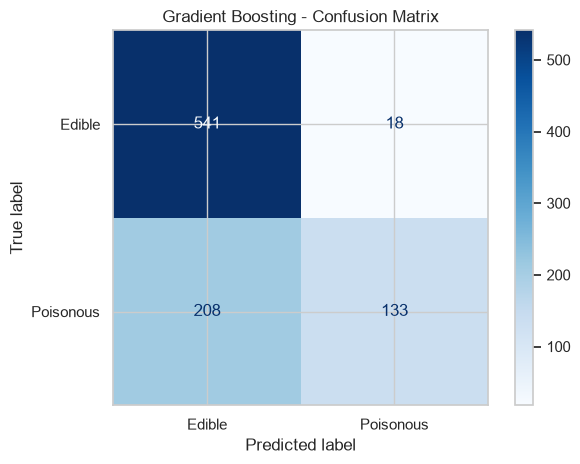

In [118]:
best_gb_model = grid_search_gb.best_estimator_

y_pred_gb_tuned = best_gb_model.predict(X_test_imputed)

print(
    "Test accuracy:",
    round(accuracy_score(y_test, y_pred_gb_tuned), 4)
)

print(classification_report(y_test, y_pred_gb_tuned))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_gb,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    cmap="Blues"
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.show()

After applying GridSearchCV, the Gradient Boosting model achieved a test accuracy of 78.11%, improving on the original model's accuracy of 74.89%. The macro-average F1-score also increased from 0.68 to 0.74, indicating more balanced performance across the two classes.

The recall for edible mushrooms (e) reached 95%, showing that the model correctly identified most edible samples. For poisonous or unknown-edibility mushrooms (p), recall improved from 39% to 50%. Although this is a meaningful improvement, the model still failed to identify half of the samples in this class.

Overall, hyperparameter tuning improved the Gradient Boosting model's performance, particularly its ability to identify class p. However, it still underperformed compared with the optimized Random Forest model.

## 2.3 - Logistic Regression Classifier

Logistic Regression will be tested as another classification model. Unlike Random Forest and Gradient Boosting, Logistic Regression is a linear model that estimates the probability of a sample belonging to a class.

In [119]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

For one final time, we prepare the mushroom data by transforming the missing values into a suitable format. This preprocessing pipeline operates almost identical to the ones we've seen before.

When we combine everything into the pipeline, we get the choice to change the iteration limit. In our example we allow up to 2000 iterations for the algorithm to converge.

In [120]:
numeric_cols = X_train_imputed.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train_imputed.select_dtypes(exclude="number").columns.tolist()

logistic_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

logistic_pipeline = Pipeline([
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

Like with previous gridsearches, we make another parameter grid. C controls the strength of the regularization, solver specifies the optimization algorithm, and penalty determines the type of regularization.

In [121]:
param_grid_lr = [
    {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["lbfgs"],
        "classifier__penalty": ["l2"]
    },
    {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["liblinear"],
        "classifier__penalty": ["l1", "l2"]
    }
]

In [122]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "f1_macro": "f1_macro",
    "recall_p": make_scorer(recall_score, pos_label="p")
}

grid_search_lr = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid_lr,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [123]:
grid_search_lr.fit(X_train_imputed, y_train)

print("Best parameters:")
print(grid_search_lr.best_params_)

print(
    "Best cross-validation macro F1-score:",
    round(grid_search_lr.best_score_, 4)
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters:
{'classifier__C': 10, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best cross-validation macro F1-score: 0.6361


c:\Users\noeye\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\noeye\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Finally, we evaluate the LR model and look for the best data results. Using best_estimator_ we retrieve the best pipeline that's refitted on the full training set.

In [124]:
best_lr_model = grid_search_lr.best_estimator_

y_pred_lr = best_lr_model.predict(X_test_imputed)

print(
    "Test accuracy:",
    round(accuracy_score(y_test, y_pred_lr), 4)
)

print(classification_report(y_test, y_pred_lr))

Test accuracy: 0.6867
              precision    recall  f1-score   support

           e       0.75      0.74      0.75       559
           p       0.58      0.60      0.59       341

    accuracy                           0.69       900
   macro avg       0.67      0.67      0.67       900
weighted avg       0.69      0.69      0.69       900



The optimized Logistic Regression model achieved a test accuracy of 68.67%, making it the weakest-performing model among the three classifiers tested so far. Its macro-average F1-score was 0.67, indicating lower overall classification performance compared with Random Forest and Gradient Boosting.

For edible mushrooms (e), the model achieved a recall of 74% and an F1-score of 0.75. For poisonous or unknown-edibility mushrooms (p), recall was 60%, meaning the model correctly identified 60% of the samples in this class. Although this is higher than the 50% recall achieved by the tuned Gradient Boosting model, it remains below the 70% recall of the optimized Random Forest.

Overall, Logistic Regression provides a simpler, more interpretable baseline, but its predictive performance is lower than that of the optimized Random Forest. Based on the current test results, Random Forest remains the strongest model, with the highest accuracy, macro F1-score, and recall for class p.

## 3 - Pycaret comparison

After training and evaluating Logistic Regression, Random Forest, and Gradient Boosting individually, PyCaret is used to compare their performance within a consistent machine learning workflow.

The objective of this section is to determine which classification algorithm performs best at predicting whether a mushroom is edible (e) or poisonous or of unknown edibility (p).

In [125]:
from pycaret.classification import (
    setup,
    compare_models,
    pull,
    create_model,
    add_metric
)
from sklearn.metrics import f1_score

ModuleNotFoundError: No module named 'pycaret'

The dataset is prepared by removing the jumbled_noise_0 feature, which was excluded in earlier assignment. The column names are also standardized by removing unnecessary spaces, converting them to lowercase, and replacing hyphens with underscores. The target variable, class, is retained so that the models can learn to distinguish between the two mushroom categories.

In [ ]:
data = mush.drop(
    columns=["jumbled_noise_0"],
    errors="ignore"
).copy()

data.columns = (
    data.columns.str.strip()
    .str.lower()
    .str.replace("-", "_", regex=False)
)

print(data.shape)
print(data["class"].value_counts())

The setu function configures the classification experiment. The dataset is divided into training and testing sets. Five-fold cross-validation is configured to evaluate the models across multiple training and validation splits. A fixed random seed is used to improve reproducibility, and the poisonous class is specified as the positive class for applicable binary classification metrics.

Macro F1-score is added as an evaluation metric to provide a balanced assessment of the two classes. It is calculated by determining the F1-score for each class separately and then averaging the results equally.

The compare_models() function is used to evaluate Logistic Regression, Random Forest, and Gradient Boosting under the same PyCaret experiment settings. Their performance is assessed using cross-validation, and the results are ranked according to macro F1-score. This makes it easier to identify which algorithm provides the best balance between precision and recall across both classes.

In [ ]:
clf = setup(
    data=data,
    target="class",
    train_size=0.82,
    fold=5,
    session_id=42,
    positive_label="p",
    index=False,
    verbose=False
)

add_metric(
    id="macro_f1",
    name="Macro F1",
    score_func=f1_score,
    target="pred",
    average="macro"
)

best_models = compare_models(
    include=["lr", "rf", "gbc"],
    sort="Macro F1",
    n_select=3,
    errors="ignore"
)

comparison_results = pull()
comparison_results

all_models = compare_models(
    sort="Macro F1",
    n_select=5,
    errors="ignore"
)

all_comparison_results = pull()
all_comparison_results

RESULTS AND CONCLUSION

## GEN-AI Disclaimer

Generative AI tools were used to support the creation of this assignment, including assistance with writing code (such as GridSearchCV and preprocessing pipelines), explaining code, and providing feedback and suggestions for improving the written documentation.

The authors reviewed the final content and retained responsibility for the implementation, analysis, interpretation of results, and conclusions presented in this assignment.